# 03 · Tratamento — Integração dengue × clima

**Camada 2 do ETL — Tratamento (integração).** Une as duas fontes na mesma granularidade:
**município × semana epidemiológica**.

| | |
|---|---|
| **Entrada** | `data/02_tratamento/datasus/*` e `data/02_tratamento/inmet/*` |
| **Saída** | `data/02_tratamento/integrado/`: `estacao_municipio.parquet`, `clima_semanal_municipio.parquet`, `painel_dengue_semanal.parquet`, `painel_dengue_clima_semanal.parquet` |
| **Próxima etapa** | `03_disponibilizacao/01_camada_semantica_e_analises.ipynb` |

**Como ligar uma estação a um município?** O INMET identifica a estação por nome e UF (ex.:
`SAO PAULO - MIRANTE`, `GOIANIA`), e o SINAN por código IBGE + nome. Fazemos a correspondência pelo
**nome normalizado dentro da mesma UF** (sem acentos, com abreviações expandidas e alguns apelidos
conferidos manualmente). Municípios com mais de uma estação recebem a **média** delas.

**Incidência** = casos ÷ população × 100 mil habitantes — permite comparar municípios de tamanhos
diferentes (recomendação da própria fonte: usar local de residência).

In [1]:
import re
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import epi  # noqa: E402
import viz  # noqa: E402
from config import ANO_FIM, FIGURAS, TRATAMENTO  # noqa: E402

viz.aplicar_estilo()
SAIDA = TRATAMENTO / "integrado"
SAIDA.mkdir(parents=True, exist_ok=True)

municipios = pd.read_parquet(TRATAMENTO / "datasus" / "municipios.parquet")
dengue = pd.read_parquet(TRATAMENTO / "datasus" / "dengue_municipio_semana.parquet")
pop = pd.read_parquet(TRATAMENTO / "datasus" / "populacao_municipio_ano.parquet")
estacoes = pd.read_parquet(TRATAMENTO / "inmet" / "estacoes.parquet")
clima_est = pd.read_parquet(TRATAMENTO / "inmet" / "inmet_semanal_estacao.parquet")

## 1. Estação → município

In [2]:
def normalizar(s: str) -> str:
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper()
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9 ]", " ", s)).strip()


def candidatos(nome: str) -> list[str]:
    """Nome completo primeiro (preserva 'GUARDA-MOR'); depois só a parte antes de ' - ' ou '('."""
    s = str(nome).upper().replace("_", " ")
    s = re.sub(r"^(DTCEA|PEF|CRMN|EB PEF|EB)\s+", "", s.strip())   # prefixos militares/aeronáuticos
    s = re.sub(r"^S\.\s*J\.\s*", "SAO JOSE ", s)
    s = re.sub(r"^S\.\s*G\.\s*", "SAO GABRIEL ", s)
    s = re.sub(r"^MAL\.\s*", "MARECHAL ", s)
    return [normalizar(s), normalizar(re.split(r"\s*-\s*|\(", s)[0])]


# Apelidos conferidos manualmente (nome da estação difere da grafia oficial do município)
APELIDOS = {
    ("TO", "MARIANOPOLIS DO TO"): "MARIANOPOLIS DO TOCANTINS",
    ("PE", "ARCO VERDE"): "ARCOVERDE",
    ("PI", "BOM JESUS DO PIAUI"): "BOM JESUS",
    ("SP", "SAO LUIZ DO PARAITINGA"): "SAO LUIS DO PARAITINGA",
    ("RS", "SANTANA DO LIVRAMENTO"): "SANT ANA DO LIVRAMENTO",
    ("MT", "CAMPO NOVO DOS PARECIS"): "CAMPO NOVO DO PARECIS",
    ("MT", "COMODORO NORTE"): "COMODORO",
}
indice = {(u, normalizar(n)): c for u, n, c in zip(municipios.sigla_uf, municipios.nome_municipio, municipios.cod_municipio)}


def municipio_da_estacao(uf: str, nome: str) -> str | None:
    if uf == "DF":
        return "530010"  # o DF tem um único município (Brasília)
    for cand in candidatos(nome):
        cand = APELIDOS.get((uf, cand), cand)
        if (uf, cand) in indice:
            return indice[(uf, cand)]
    return None


estacoes["cod_municipio"] = [municipio_da_estacao(u, n) for u, n in zip(estacoes.sigla_uf, estacoes.nome_estacao)]
est_mun = estacoes[["codigo_wmo", "nome_estacao", "sigla_uf", "cod_municipio", "latitude", "longitude"]]
est_mun.to_parquet(SAIDA / "estacao_municipio.parquet", index=False)

ok = estacoes["cod_municipio"].notna()
print(f"{ok.sum()} de {len(estacoes)} estações associadas a um município ({ok.mean():.1%}) → "
      f"{estacoes.cod_municipio.nunique()} municípios com estação.".replace(".", ",", 1))
print("Sem município (ilhas, faróis, parques, áreas militares e a estação antártica 'Criosfera'):")
print(", ".join(f"{n}/{u}" for n, u in zip(estacoes[~ok].nome_estacao, estacoes[~ok].sigla_uf)))

680 de 705 estações associadas a um município (96,5%) → 651 municípios com estação.
Sem município (ilhas, faróis, parques, áreas militares e a estação antártica 'Criosfera'):
PARQUE ESTADUAL CHANDLESS/AC, RIO URUBU/AM, FAROL de SANTANA/MA, PREGUICAS/MA, SERRA DOS CARAJAS/PA, MINA DO PALITO/PA, ARQ.SAO PEDRO E SAO PAULO/RN, SAO GONCALO/PB, CALCANHAR/RN, CAMARATUBA/PB, ABROLHOS/BA, DELFINO/BA, MONTE VERDE/MG, MOCAMBINHO/MG, PICO DO COUTO/RJ, NHUMIRIM/MS, ILHA DO MEL/PR, ESPIGAO DO LESTE/MT, PARQUE ELDORADO/RS, CRIOSFERA/SP, FORTE PRINCIPE/RO, PEF IPIRANGA/AM, BALIZA/RR, PEF YAUARETE/AM, PEF ESTIRAO DO EQUADOR/AM


## 2. Clima semanal por município

In [3]:
VARS_CLIMA = ["precipitacao_mm", "precipitacao_max_diaria_mm", "dias_chuva", "temp_media_c", "temp_max_media_c",
              "temp_min_media_c", "temp_max_absoluta_c", "umidade_media_pct", "orvalho_media_c"]
c = clima_est.merge(est_mun[["codigo_wmo", "cod_municipio"]].dropna(), on="codigo_wmo")
clima_mun = c.groupby(["cod_municipio", "id_semana"])[VARS_CLIMA].mean()
clima_mun["n_estacoes"] = c[c["temp_media_c"].notna()].groupby(["cod_municipio", "id_semana"])["codigo_wmo"].nunique()
clima_mun["n_estacoes"] = clima_mun["n_estacoes"].fillna(0).astype("int8")
clima_mun = clima_mun.reset_index()
clima_mun.to_parquet(SAIDA / "clima_semanal_municipio.parquet", index=False)
print(f"{viz.fmt_br(len(clima_mun))} município-semanas com clima | "
      f"municípios com 2+ estações: {(est_mun.groupby('cod_municipio').size() > 1).sum()}")

353.464 município-semanas com clima | municípios com 2+ estações: 21


## 3. Painel de dengue com incidência (todos os municípios)

Dados de 2026 são **preliminares** (sujeitos a revisão) e as últimas semanas publicadas sofrem
**atraso de notificação** — casos ainda serão digitados. Marcamos as 4 últimas semanas para que as
análises possam excluí-las.

In [4]:
painel = dengue.merge(pop.rename(columns={"ano": "ano_epi"}), on=["cod_municipio", "ano_epi"], how="left")
assert painel.loc[painel["populacao"].isna(), "casos"].sum() == 0  # só falta população onde não há casos
painel["incidencia_100k"] = (painel["casos"] / painel["populacao"] * 1e5).astype("float32")
ultima = painel["id_semana"].max()
ultimas4 = sorted(painel["id_semana"].unique())[-4:]
painel["dado_preliminar"] = painel["ano_epi"] == ANO_FIM
painel["atraso_notificacao"] = painel["id_semana"].isin(ultimas4)
painel.to_parquet(SAIDA / "painel_dengue_semanal.parquet", index=False)
print(f"Painel: {viz.fmt_br(len(painel))} linhas | última semana: {ultima} | semanas com atraso: {[int(s) for s in ultimas4]}")

Painel: 3.738.141 linhas | última semana: 202644 | semanas com atraso: [202641, 202642, 202643, 202644]


## 4. Painel dengue × clima (municípios com estação)

Partimos do painel de dengue (todas as semanas, inclusive as com zero casos) e anexamos o clima.
Assim a série de cada município fica **contínua no tempo** — requisito para calcular defasagens
("a chuva de 4 semanas atrás") na próxima camada.

In [5]:
com_estacao = set(clima_mun["cod_municipio"])
pdc = painel[painel["cod_municipio"].isin(com_estacao)].merge(clima_mun, on=["cod_municipio", "id_semana"], how="left")
pdc["n_estacoes"] = pdc["n_estacoes"].fillna(0).astype("int8")
pdc = pdc.sort_values(["cod_municipio", "id_semana"]).reset_index(drop=True)
pdc.to_parquet(SAIDA / "painel_dengue_clima_semanal.parquet", index=False)
print(f"{pdc.cod_municipio.nunique()} municípios × {pdc.id_semana.nunique()} semanas = {viz.fmt_br(len(pdc))} linhas | "
      f"semanas com temperatura válida: {viz.fmt_br(pdc.temp_media_c.notna().mean() * 100, 1)}%")
pdc.head()

651 municípios × 671 semanas = 436.821 linhas | semanas com temperatura válida: 64,0%


,cod_municipio,id_semana,ano_epi,semana_epi,casos,populacao,populacao_repetida,incidencia_100k,dado_preliminar,atraso_notificacao,precipitacao_mm,precipitacao_max_diaria_mm,dias_chuva,temp_media_c,temp_max_media_c,temp_min_media_c,temp_max_absoluta_c,umidade_media_pct,orvalho_media_c,n_estacoes
0,110002,201401,2014,1,3,97496,False,3.077049,False,False,NaN,NaN,NaN,25.932293,32.250000,22.950001,33.500000,85.177086,23.002083,1
1,110002,201402,2014,2,0,97496,False,0.000000,False,False,51.799999,17.600000,6.0,25.147617,30.100000,22.557142,31.600000,86.226189,22.520832,1
2,110002,201403,2014,3,3,97496,False,3.077049,False,False,44.200001,20.000000,5.0,24.933332,31.285715,22.542858,32.500000,88.089287,22.676786,1
3,110002,201404,2014,4,4,97496,False,4.102732,False,False,21.000000,10.799999,5.0,25.387499,30.442856,22.814285,32.099998,87.011902,22.930952,1
4,110002,201405,2014,5,4,97496,False,4.102732,False,False,130.800003,61.400002,5.0,24.876785,29.885714,22.257143,32.200001,86.946426,22.392857,1


### 4.1 Representatividade
Os municípios com estação são poucos, mas grandes: concentram uma fatia muito maior da população
e dos casos do que do número de municípios. É o recorte em que o cruzamento clima × dengue é possível.

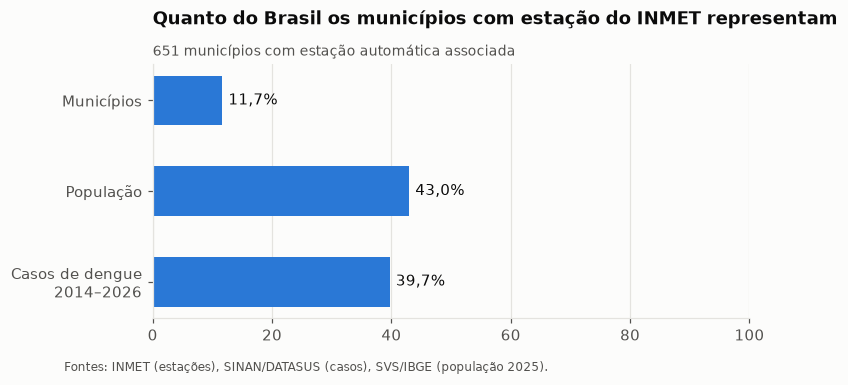

,% do Brasil
Municípios,11.7
População,43.0
Casos de dengue\n2014–2026,39.7


In [6]:
pop25 = municipios.set_index("cod_municipio")[municipios.columns[municipios.columns.str.startswith("populacao_")][0]]
casos_mun = dengue.groupby("cod_municipio")["casos"].sum()
rep = pd.Series({
    "Municípios": len(com_estacao) / len(municipios) * 100,
    "População": pop25[pop25.index.isin(com_estacao)].sum() / pop25.sum() * 100,
    "Casos de dengue\n2014–2026": casos_mun[casos_mun.index.isin(com_estacao)].sum() / casos_mun.sum() * 100,
})
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(rep.index[::-1], rep.values[::-1], color=viz.AZUL, height=0.55)
for y, v in enumerate(rep.values[::-1]):
    ax.text(v + 1, y, f"{viz.fmt_br(v, 1)}%", va="center", fontsize=10)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Quanto do Brasil os municípios com estação do INMET representam")
viz.subtitulo(ax, f"{len(com_estacao)} municípios com estação automática associada")
viz.fonte(fig, "Fontes: INMET (estações), SINAN/DATASUS (casos), SVS/IBGE (população 2025).")
viz.salvar(fig, "integracao_representatividade", FIGURAS)
plt.show()
rep.round(1).rename("% do Brasil").to_frame()

Próximo passo: **`03_disponibilizacao/01_camada_semantica_e_analises.ipynb`** — camada semântica
(fatos e dimensões para o Power BI), análises, hipóteses e métricas finais.